In [ ]:
pip install qiskit qiskit-aer matplotlib

In [ ]:
# 2. Tackle Noise with Error Correction


Quantum Teleportation Results:
{'111': 256, '110': 212, '100': 267, '101': 265}


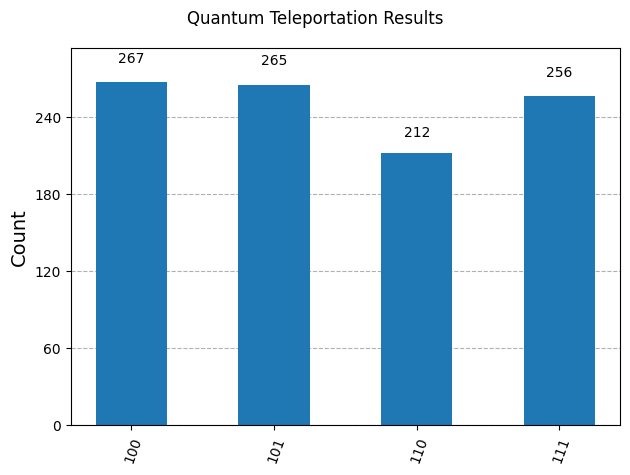

In [ ]:
# Practical 2: Quantum Teleportation Algorithm

# Step 1: Import required libraries
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Step 2: Create a quantum circuit
# 3 Quantum bits and 3 Classical bits
circuit = QuantumCircuit(3, 3)

# Step 3: Apply X gate to the qubit to be teleported
circuit.x(0)
circuit.barrier()

# Step 4: Create entanglement between Q1 and Q2
circuit.h(1)
circuit.cx(1, 2)

# Step 5: Apply CNOT gate between Q0 and Q1
circuit.cx(0, 1)

# Step 6: Apply Hadamard gate to Q0
circuit.h(0)
circuit.barrier()

# Step 7: Measure Q0 and Q1
circuit.measure([0, 1], [0, 1])

# Step 8: Apply correction gates
circuit.barrier()
circuit.cx(1, 2)  # Controlled-X gate
circuit.cz(0, 2)  # Controlled-Z gate

# Step 9: Measure the receiver's qubit Q2
circuit.measure(2, 2)

# # Display the quantum circuit
# print("\nQuantum Teleportation Circuit:")
# print(circuit.draw())

# Step 10: Initialize the simulator
simulator = AerSimulator()

# Step 11: Transpile the circuit
compiled_circuit = transpile(circuit, simulator)

# Step 12: Execute the circuit with 1000 shots
job = simulator.run(compiled_circuit, shots=1000)

# Step 13: Get the measurement results
result = job.result()
counts = result.get_counts()

# Step 14: Display the results
print("\nQuantum Teleportation Results:")
print(counts)

# Step 15: Plot the histogram
fig = plot_histogram(counts)

# Set proper title and spacing
fig.suptitle("Quantum Teleportation Results")
fig.tight_layout()

# Display histogram
display(fig)
